# HW 02: Retrieval with TF-IDF, BM25, and LSA, Word2Vec (CBOW), and Ranking Evaluation

### This homework has three tasks:
1) Ranked retrieval with TF-IDF, BM25, and LSA on 20 Newsgroups posts — **6 pts**
2) Word2Vec (CBOW) with PyTorch on posts of the same newsgroups, and ranking with CBOW — **7 pts**
3) Evaluation with P@k, R@k, and MRR: TF-IDF vs BM25 vs LSA vs CBOW — **7 pts**

**BONUS:** Solve any task with an LLM — **2 pts**

#### Total: 20 points (+2 bonus)

**Rules**
- Complete only the regions between `## YOUR_CODE_STARTS_HERE` and `## YOUR_CODE_ENDS_HERE`. Do not change the provided code, function signatures, seeds, or hyperparameters.
- The code follows PS 03 and PS 04 (e.g., `TfidfVectorizer`, `BM25Okapi`, `TruncatedSVD`, the Skip-gram model with `in_embed` and `out`, the training step, `calculate_precision_at_k`, `rr_score`), so you can look up similar code there.
- All tasks are deterministic: if you follow the instructions, your printed output matches the `TESTS & EXPECTED OUTPUT` cell after each task (It's normal if there are minor differences in the decimal points since floating point calculations can differ based on the hardware).
- **Hardcoding answers to match the expected output (e.g., returning fixed values or special-casing inputs) gives 0 points for the whole task.**

## Pre-requisite code

The code in this section will be used in the tasks. **Do not change these lines.**

The Task 1 and Task 2 data cells need internet access: they download the 20 Newsgroups dataset with scikit-learn (about 14 MB, once).

In [1]:
# Colab setup: NumPy, scikit-learn, and PyTorch are pre-installed in Google Colab.
# This cell installs rank_bm25, the BM25 library, if it is missing.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rank_bm25") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rank_bm25==0.2.2"])

print(f"Python: {sys.version.split()[0]}")
print("rank_bm25 is ready")

Python: 3.14.7
rank_bm25 is ready


In [2]:
# Shared imports and seeds.
import math
import random
import warnings
from collections import Counter
from dataclasses import dataclass
from typing import Callable

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from rank_bm25 import BM25Okapi
from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from torch.utils.data import DataLoader, TensorDataset

# TfidfVectorizer warns that its default token_pattern is unused when we pass our own tokenizer; that is intended.
warnings.filterwarnings("ignore", message="The parameter 'token_pattern' will not be used")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Shared helpers are ready")

Shared helpers are ready


### Task 1: data and helpers

The next cell prepares everything Task 1 needs:
- `tokenize(text)`: lowercase, split on whitespace, and keep only the **letters and digits** of every token. About a fifth of the raw tokens carry punctuation or symbols (`failures,`, `them.`, `(and`, `don't`); without this step, `failures,` in a query would not match `failures` in a post. No stopwords are removed, because TF-IDF and BM25 down-weight frequent words through IDF;
- `Doc` and `collect_subset(...)`: load 20 Newsgroups posts of four newsgroups (`mac`, `space`, `autos`, `hockey`) with scikit-learn, keep posts with at least 10 tokens, and cut them to their first 50 tokens;
- `TEST_DOCS`: the retrieval collection, 25 posts per newsgroup from the official test split; a document ID is a position in `TEST_DOCS`;
- `QUERIES`: four `(query_text, label)` pairs, one per newsgroup;
- `cosine(a, b)` and `rank_by_score(scores)`: all IDs sorted by score, highest first; equal scores keep the ascending ID order;
- prints the collection size per newsgroup, post 0, and the first query with its tokens.

In [3]:
# Task 1 data: 20 Newsgroups (Lang, 1995), public posts of four Usenet newsgroups, loaded with scikit-learn
# We keep the first posts of every group with at least 10 tokens and cut every post to its first 50 tokens.
CATEGORIES = ["comp.sys.mac.hardware", "sci.space", "rec.autos", "rec.sport.hockey"]
LABEL_MAP = {"comp.sys.mac.hardware": "mac", "sci.space": "space", "rec.autos": "autos", "rec.sport.hockey": "hockey"}
TEST_PER_CLASS = 25     # posts per group in the retrieval collection
MIN_TOKENS_PER_DOC = 10
MAX_TOKENS_PER_DOC = 50


def tokenize(text: str) -> list[str]:
    """Lowercase, split on whitespace, and keep only the letters and digits of every token (e.g. 'failures,' -> 'failures')."""
    tokens = []
    for token in text.lower().split():
        token = "".join(ch for ch in token if ch.isalnum())
        if token:
            tokens.append(token)
    return tokens


@dataclass
class Doc:
    text: str
    tokens: list[str]
    label: str  # short newsgroup name; a post is relevant for a query with the same label


def collect_subset(subset: str, per_class: int) -> list[Doc]:
    """Return the first per_class posts of every group with at least MIN_TOKENS_PER_DOC tokens, in CATEGORIES order."""
    dataset = fetch_20newsgroups(subset=subset, categories=CATEGORIES, remove=("headers", "footers", "quotes"),
                                 shuffle=False)
    by_class = {category: [] for category in CATEGORIES}
    for text, target in zip(dataset.data, dataset.target):
        category = dataset.target_names[target]
        tokens = tokenize(text)[:MAX_TOKENS_PER_DOC]
        if len(tokens) >= MIN_TOKENS_PER_DOC and len(by_class[category]) < per_class:
            by_class[category].append(Doc(text=" ".join(tokens), tokens=tokens, label=LABEL_MAP[category]))
    return [doc for category in CATEGORIES for doc in by_class[category]]


def cosine(a: np.ndarray, b: np.ndarray) -> float:
    """Cosine similarity of two vectors; 0.0 if one of them is the zero vector."""
    norm_a = float(np.linalg.norm(a))
    norm_b = float(np.linalg.norm(b))
    if norm_a == 0.0 or norm_b == 0.0:
        return 0.0
    return float(np.dot(a, b)) / (norm_a * norm_b)


def rank_by_score(scores: list[float] | np.ndarray) -> list[int]:
    """Return all document IDs, the highest score first.

    scores holds one score per document (a list or a NumPy array). sorted() keeps the original order of equal
    keys, so documents with equal scores stay in ascending ID order.
    """
    doc_ids = list(range(len(scores)))
    return sorted(doc_ids, key=lambda doc_id: scores[doc_id], reverse=True)


TEST_DOCS = collect_subset("test", TEST_PER_CLASS)  # the retrieval collection; document ID = position in TEST_DOCS

# One search query per newsgroup; the relevant posts of a query are the posts of its newsgroup.
QUERIES = [
    ("how do i fix problems on my mac like disk failures, monitor issues and software failures", "mac"),
    ("latest updates on nasa missions space shuttle launches and orbital science experiments", "space"),
    ("advice on car performance engine reliability and buying a new vehicle", "autos"),
    ("discussion about hockey teams playoffs goalies and physical play on the ice", "hockey"),
]

print(f"Task 1: {len(TEST_DOCS)} posts in the retrieval collection "
      f"({', '.join(f'{label}: {sum(doc.label == label for doc in TEST_DOCS)}' for label in LABEL_MAP.values())})")
print(f"Post 0 ({TEST_DOCS[0].label}, {len(TEST_DOCS[0].tokens)} tokens): {TEST_DOCS[0].text}")
print(f"{len(QUERIES)} queries, e.g. ({QUERIES[0][1]}): {QUERIES[0][0]}")
print(f"Its tokens: {tokenize(QUERIES[0][0])}")

Task 1: 100 posts in the retrieval collection (mac: 25, space: 25, autos: 25, hockey: 25)
Post 0 (mac, 26 tokens): dont forget the lamg los angeles macintosh group bbs its the bbs for the largest maconly user group in the country now that bmug is multiplatform
4 queries, e.g. (mac): how do i fix problems on my mac like disk failures, monitor issues and software failures
Its tokens: ['how', 'do', 'i', 'fix', 'problems', 'on', 'my', 'mac', 'like', 'disk', 'failures', 'monitor', 'issues', 'and', 'software', 'failures']


### Task 2: data and helpers

The next cell prepares everything Task 2 needs:
- `TRAIN_DOCS`: 100 posts per newsgroup from the official training split, prepared like `TEST_DOCS`, and `train_tokenized`, their token lists;
- `w2i` (word → ID) and `i2w` (ID → word): the sorted vocabulary of the training posts;
- `CBOWModelTorch`: the container of a trained model (`w2i`, `i2w`, `model`, `dim`, `window`, `losses`);
- prints the number of training posts, the vocabulary size, and the first tokens of training post 0 with their IDs.

In [4]:
# Task 2 data: training posts of the same four newsgroups, their vocabulary, and the container of a trained
# CBOW model.
TRAIN_PER_CLASS = 100   # training posts per group
TRAIN_DOCS = collect_subset("train", TRAIN_PER_CLASS)
train_tokenized = [doc.tokens for doc in TRAIN_DOCS]

# Sorted vocabulary: word -> ID and ID -> word
vocabulary = sorted({token for tokens in train_tokenized for token in tokens})
w2i = {word: index for index, word in enumerate(vocabulary)}
i2w = {index: word for word, index in w2i.items()}


@dataclass
class CBOWModelTorch:
    """A trained CBOW model with its vocabulary, settings, and the training loss of every epoch."""
    w2i: dict[str, int]
    i2w: dict[int, str]
    model: nn.Module
    dim: int
    window: int
    losses: list[float]


print(f"Task 2: {len(TRAIN_DOCS)} training posts ({TRAIN_PER_CLASS} per newsgroup), vocabulary of {len(w2i)} words")
print("First tokens of training post 0:", train_tokenized[0][:8])
print("Their IDs:                       ", [w2i[token] for token in train_tokenized[0][:8]])

Task 2: 400 training posts (100 per newsgroup), vocabulary of 4407 words
First tokens of training post 0: ['well', 'i', 'just', 'got', 'my', 'centris', '610', 'yesterday']
Their IDs:                        [4276, 1956, 2145, 1765, 2612, 833, 213, 4379]


### Task 3: data and helpers

The next cell prepares everything Task 3 needs. **Task 3 does not use your code from Tasks 1 and 2.**
- `RANKINGS`: the rankings that Task 3 evaluates. We computed them **once** with the reference solution of Tasks 1 and 2 and wrote them into the cell, so they are the same for everyone, whatever your Tasks 1 and 2 return. For every ranker (TF-IDF, BM25, LSA, CBOW) there is one entry per query with its `query_id` (`q1` to `q4`, in the order of `QUERIES`), its `label`, and its `ranking`: the IDs of the **25 posts** the ranker puts first, best first. We keep 25 posts because every query has 25 relevant posts.
- `relevant_doc_indices(docs, label)` and `RELEVANT_SETS`: the IDs of the relevant posts of every query (the 25 posts of the query's newsgroup), by `query_id`;
- prints every query with its ID, label, and number of relevant posts, and the start of one ranking.

In [5]:
# Task 3 data: the rankings that Task 3 evaluates, and the relevant posts of every query.
#
# RANKINGS is FIXED INPUT for Task 3. We computed it once with the reference solution of Tasks 1 and 2 and wrote
# it into this cell: it is the same for everyone and does NOT depend on your code in Tasks 1 and 2.
RANKINGS = {
    "TF-IDF": [
        {"query_id": "q1", "label": "mac", "ranking": [17, 57, 24, 69, 48, 72, 4, 18, 68, 9, 82, 29, 49, 41, 99, 20,
                                                       44, 19, 3, 97, 96, 23, 84, 1, 58]},
        {"query_id": "q2", "label": "space", "ranking": [48, 84, 33, 28, 26, 46, 21, 19, 65, 60, 70, 12, 73, 68, 67,
                                                         89, 63, 17, 40, 18, 7, 50, 8, 94, 13]},
        {"query_id": "q3", "label": "autos", "ranking": [70, 19, 67, 41, 15, 64, 22, 59, 97, 73, 68, 7, 1, 65, 93,
                                                         72, 60, 57, 61, 12, 21, 69, 45, 17, 58]},
        {"query_id": "q4", "label": "hockey", "ranking": [82, 89, 84, 75, 91, 97, 96, 95, 30, 63, 73, 19, 88, 28,
                                                          65, 60, 72, 21, 70, 64, 68, 67, 61, 12, 48]},
    ],
    "BM25": [
        {"query_id": "q1", "label": "mac", "ranking": [24, 17, 4, 69, 9, 48, 57, 18, 72, 3, 41, 29, 99, 68, 82, 23,
                                                       20, 44, 97, 95, 96, 49, 27, 75, 86]},
        {"query_id": "q2", "label": "space", "ranking": [48, 84, 33, 26, 28, 46, 21, 19, 17, 63, 67, 68, 89, 12, 60,
                                                         70, 7, 8, 18, 35, 50, 94, 13, 20, 36]},
        {"query_id": "q3", "label": "autos", "ranking": [70, 67, 19, 41, 15, 64, 22, 97, 68, 59, 1, 7, 61, 58, 93,
                                                         73, 57, 69, 72, 17, 12, 21, 60, 45, 63]},
        {"query_id": "q4", "label": "hockey", "ranking": [75, 97, 89, 84, 82, 91, 30, 96, 95, 63, 88, 73, 64, 28,
                                                          19, 21, 61, 72, 48, 60, 67, 68, 32, 39, 70]},
    ],
    "LSA": [
        {"query_id": "q1", "label": "mac", "ranking": [72, 19, 69, 20, 97, 62, 85, 3, 44, 17, 6, 12, 5, 57, 23, 68,
                                                       1, 98, 65, 29, 55, 58, 24, 70, 39]},
        {"query_id": "q2", "label": "space", "ranking": [48, 18, 50, 60, 21, 32, 28, 86, 0, 98, 46, 13, 64, 75, 9,
                                                         33, 7, 34, 65, 89, 84, 67, 91, 58, 73]},
        {"query_id": "q3", "label": "autos", "ranking": [70, 61, 69, 97, 73, 12, 55, 72, 65, 57, 54, 56, 5, 64, 98,
                                                         4, 49, 71, 3, 66, 13, 18, 67, 60, 19]},
        {"query_id": "q4", "label": "hockey", "ranking": [89, 91, 82, 37, 39, 98, 94, 65, 18, 96, 51, 54, 73, 84,
                                                          95, 67, 60, 64, 0, 12, 31, 26, 88, 70, 41]},
    ],
    "CBOW": [
        {"query_id": "q1", "label": "mac", "ranking": [99, 19, 81, 57, 20, 32, 17, 86, 29, 21, 1, 58, 23, 39, 85,
                                                       45, 59, 24, 94, 72, 68, 64, 26, 87, 78]},
        {"query_id": "q2", "label": "space", "ranking": [48, 42, 50, 26, 86, 1, 17, 39, 76, 83, 87, 74, 88, 21, 32,
                                                         81, 78, 51, 19, 46, 94, 29, 18, 16, 10]},
        {"query_id": "q3", "label": "autos", "ranking": [17, 81, 19, 39, 1, 21, 26, 85, 18, 70, 29, 58, 55, 46, 42,
                                                         79, 24, 88, 59, 86, 61, 50, 64, 94, 87]},
        {"query_id": "q4", "label": "hockey", "ranking": [26, 76, 67, 46, 88, 42, 94, 51, 84, 48, 16, 83, 73, 21,
                                                          82, 98, 7, 18, 95, 79, 66, 8, 17, 11, 1]},
    ],
}


def relevant_doc_indices(docs: list[Doc], label: str) -> set[int]:
    """Return the IDs of the posts in docs whose label matches the query label."""
    return {doc_id for doc_id, doc in enumerate(docs) if doc.label == label}


# The relevant posts of every query: the posts of the query's newsgroup, by query ID
RELEVANT_SETS = {f"q{i}": relevant_doc_indices(TEST_DOCS, label) for i, (_, label) in enumerate(QUERIES, start=1)}

print("Task 3: the four queries")
for query_id, (query_text, label) in zip(RELEVANT_SETS, QUERIES):
    print(f"  {query_id} ({label}, {len(RELEVANT_SETS[query_id])} relevant posts): {query_text}")
first = RANKINGS["TF-IDF"][0]
print(f"Rankers: {', '.join(RANKINGS)}; e.g. TF-IDF, {first['query_id']} ({first['label']}): "
      f"the first 10 of {len(first['ranking'])} post IDs {first['ranking'][:10]}")

Task 3: the four queries
  q1 (mac, 25 relevant posts): how do i fix problems on my mac like disk failures, monitor issues and software failures
  q2 (space, 25 relevant posts): latest updates on nasa missions space shuttle launches and orbital science experiments
  q3 (autos, 25 relevant posts): advice on car performance engine reliability and buying a new vehicle
  q4 (hockey, 25 relevant posts): discussion about hockey teams playoffs goalies and physical play on the ice
Rankers: TF-IDF, BM25, LSA, CBOW; e.g. TF-IDF, q1 (mac): the first 10 of 25 post IDs [17, 57, 24, 69, 48, 72, 4, 18, 68, 9]


# TASK 1 (6 pts): Ranked retrieval with TF-IDF, BM25, and LSA

**High-level overview.**
Build three rankers on a retrieval collection of **100 real newsgroup posts** (`TEST_DOCS`, 25 per newsgroup) and rank all posts for four search queries, one per newsgroup. The rankers are the ones of **PS 03**: **TF-IDF** (`TfidfVectorizer`), **BM25** (`BM25Okapi` from `rank_bm25`), and **LSA** (`TruncatedSVD` on the TF-IDF matrix). Here you compare their top-5 posts.

| Ranker | Score of post $d$ for query $q$ |
|---|---|
| TF-IDF | $\mathbf{q} \cdot \mathbf{d}$, the dot product of the TF-IDF vectors. `TfidfVectorizer` applies **L2 normalization** to every vector by default, so this dot product is their cosine |
| BM25 | $\sum_{t \in q} \mathrm{IDF}(t)\,\frac{(k_1+1)\,f(t,d)}{f(t,d)+k_1\,(1-b+b\,\mathrm{dl}/\mathrm{avgdl})}$, computed by `get_scores` |
| LSA | $\cos(\mathbf{q}_k, \mathbf{d}_k)$ of the $k$-dimensional SVD coordinates of the TF-IDF vectors ($k = 10$) |

Every ranker returns **all** document IDs (positions in `TEST_DOCS`) sorted by descending score with the provided `rank_by_score`, so equal scores keep the ascending ID order.

<img src="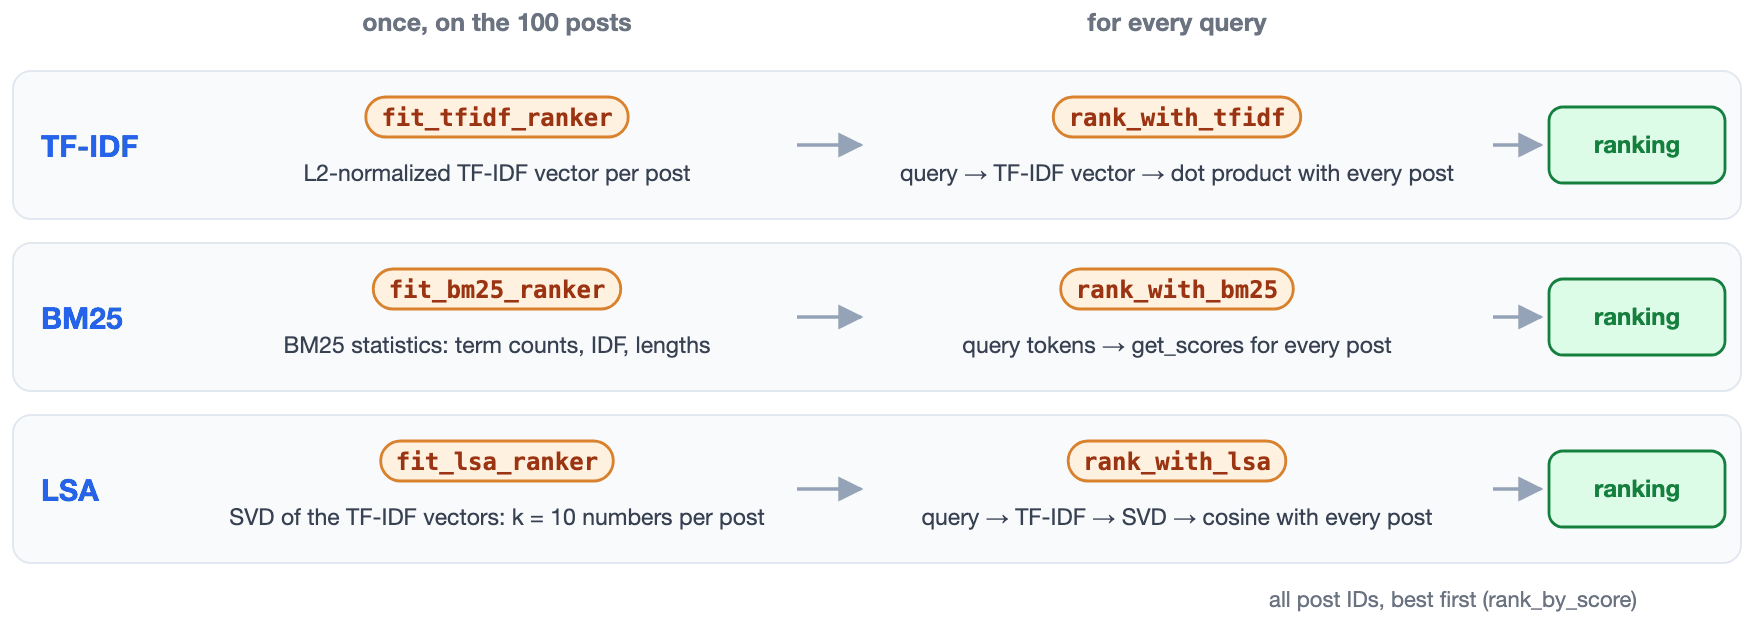" alt="Overview of the three rankers. TF-IDF: fit_tfidf_ranker builds an L2-normalized TF-IDF vector per post once; rank_with_tfidf turns the query into a TF-IDF vector and takes its dot product with every post. BM25: fit_bm25_ranker stores term counts, IDF, and lengths; rank_with_bm25 scores every post with get_scores on the query tokens. LSA: fit_lsa_ranker reduces the TF-IDF vectors with SVD to 10 numbers per post; rank_with_lsa projects the query the same way and takes the cosine with every post. Each ranker returns all post IDs, best first, with rank_by_score." width="720">

The figure shows the three rankers side by side: the function that fits each model on the posts, and the function that scores and ranks the posts for a query.

---

### What is provided
- `TEST_DOCS`: 100 `Doc`s with `text` (at most 50 lowercase tokens), `tokens`, and `label` (`mac`, `space`, `autos`, or `hockey`); `QUERIES`: four `(query_text, label)` pairs.
- `tokenize(text)`, `cosine(a, b)`, and `rank_by_score(scores)` from the Task 1 data cell.
- The `LSAModel` container (`vectorizer`, `svd`, `doc_embeddings`, `k`) and the code that builds the rankers and prints the top-5 posts of every query.

---

### What you should implement
1) `fit_tfidf_ranker` — fit `TfidfVectorizer(tokenizer=tokenizer)` (by default it applies the L2 normalization) on the texts of `docs`; return the vectorizer and the sparse TF-IDF matrix of shape `(len(docs), vocab_size)`.
2) `rank_with_tfidf` — transform the query with the **same** vectorizer, score every post by the dot product of its row with the query vector, and return `rank_by_score(scores)`.
3) `fit_bm25_ranker` — return a `BM25Okapi` model fitted on the token lists of `docs` with `k1=1.5` and `b=0.75`.
4) `rank_with_bm25` — tokenize the query with `tokenize`, score all posts with `get_scores`, and return `rank_by_score(scores)`.
5) `fit_lsa_ranker` — fit `TruncatedSVD(n_components=k, random_state=random_state)` on the TF-IDF matrix and return an `LSAModel` whose `doc_embeddings` are `svd.fit_transform(doc_matrix)`, shape `(len(docs), k)`.
6) `rank_with_lsa` — project the query with the **fitted** vectorizer and used SVD (`transform`), compute its `cosine` with every row of `doc_embeddings`, and return `rank_by_score(scores)`.

---

### Grading (6 pts)
One sub-task per function above:
- **1.1** `fit_tfidf_ranker`: the given tokenizer, L2-normalized TF-IDF matrix of shape `(len(docs), vocab_size)`; the sizes match the expected output — **1.0 pt**
- **1.2** `rank_with_tfidf`: dot-product scores, all IDs in order; the TF-IDF top-5 match the expected output — **1.0 pt**
- **1.3** `fit_bm25_ranker`: `BM25Okapi` on the tokens with `k1=1.5` and `b=0.75` — **0.5 pts**
- **1.4** `rank_with_bm25`: tokenized query, `get_scores`, all IDs in order; the BM25 top-5 match the expected output — **1.0 pt**
- **1.5** `fit_lsa_ranker`: fitted SVD with `k` components and document coordinates of shape `(len(docs), k)` — **1.0 pt**
- **1.6** `rank_with_lsa`: query projected with the fitted models, cosine scores, all IDs in order; the LSA top-5 match the expected output — **1.5 pts**

> **Tips**
> • Fit the vectorizer and the SVD once, on the posts; a query is only transformed.
> • Posts that share no word with the query score 0 with TF-IDF and BM25; `rank_by_score` puts them in ID order.

In [6]:
def fit_tfidf_ranker(docs: list[Doc], tokenizer: Callable[[str], list[str]]) -> tuple[TfidfVectorizer, csr_matrix]:
    """Fit a TfidfVectorizer that uses tokenizer on the texts of docs; return it and the L2-normalized TF-IDF matrix."""
    ## YOUR_CODE_STARTS_HERE
    Tfidf_vectorizer = TfidfVectorizer(tokenizer=tokenizer, norm='l2')
    doc_texts = [doc.text for doc in docs]
    tfidf_matrix = Tfidf_vectorizer.fit_transform(doc_texts)
    return Tfidf_vectorizer, tfidf_matrix
    ## YOUR_CODE_ENDS_HERE


def rank_with_tfidf(query_text: str, vectorizer: TfidfVectorizer, doc_matrix: csr_matrix) -> list[int]:
    """Rank all documents by the dot product of their L2-normalized TF-IDF vectors with the query's (their cosine)."""
    ## YOUR_CODE_STARTS_HERE
    query_vector = vectorizer.transform([query_text])
    similarities = doc_matrix.dot(query_vector.T).toarray().ravel()
    return rank_by_score(similarities)
    ## YOUR_CODE_ENDS_HERE


def fit_bm25_ranker(docs: list[Doc]) -> BM25Okapi:
    """Fit BM25Okapi (k1=1.5, b=0.75) on the token lists of docs."""
    ## YOUR_CODE_STARTS_HERE
    BM25_model = BM25Okapi([doc.tokens for doc in docs], k1=1.5, b=0.75)
    return BM25_model
    ## YOUR_CODE_ENDS_HERE


def rank_with_bm25(query_text: str, bm25_model: BM25Okapi) -> list[int]:
    """Rank all documents by their BM25 score for the tokenized query."""
    ## YOUR_CODE_STARTS_HERE
    query_tokens = tokenize(query_text)
    scores = bm25_model.get_scores(query_tokens)
    return rank_by_score(scores)
    ## YOUR_CODE_ENDS_HERE


@dataclass
class LSAModel:
    """The TF-IDF vectorizer of Task 1.1, the fitted TruncatedSVD, and the LSA coordinates of the documents."""
    vectorizer: TfidfVectorizer
    svd: TruncatedSVD
    doc_embeddings: np.ndarray  # (num_docs, k)
    k: int


def fit_lsa_ranker(vectorizer: TfidfVectorizer, doc_matrix: csr_matrix, k: int = 10,
                   random_state: int = RANDOM_SEED) -> LSAModel:
    """Fit TruncatedSVD with k components on the TF-IDF matrix and store the LSA coordinates of the documents."""
    k = max(1, min(k, min(doc_matrix.shape) - 1))  # TruncatedSVD needs k < min(num_docs, vocab_size)
    ## YOUR_CODE_STARTS_HERE
    svd = TruncatedSVD(n_components=k, random_state=random_state)
    doc_embeddings = svd.fit_transform(doc_matrix)
    return LSAModel(vectorizer, svd, doc_embeddings, k)
    ## YOUR_CODE_ENDS_HERE


def rank_with_lsa(query_text: str, lsa_model: LSAModel) -> list[int]:
    """Rank all documents by the cosine of their LSA coordinates with the projected query."""
    ## YOUR_CODE_STARTS_HERE
    doc_vector = lsa_model.vectorizer.transform([query_text])
    query_embedding = lsa_model.svd.transform(doc_vector)
    similarities = np.array([cosine(query_embedding.flatten(), doc_embedding) for doc_embedding in lsa_model.doc_embeddings])
    return rank_by_score(similarities) 
    ## YOUR_CODE_ENDS_HERE


# Build the three rankers on the retrieval collection
tfidf_vec, tfidf_matrix = fit_tfidf_ranker(TEST_DOCS, tokenize)
bm25_model = fit_bm25_ranker(TEST_DOCS)
lsa_model = fit_lsa_ranker(tfidf_vec, tfidf_matrix, k=10, random_state=RANDOM_SEED)
print(f"[TASK1] TF-IDF matrix {tfidf_matrix.shape} | BM25 vocabulary {len(bm25_model.idf)} | "
      f"LSA document embeddings {lsa_model.doc_embeddings.shape}")

# Rank the posts for every query and show the top 5 of each ranker
top5_ids = {}
for query_text, label in QUERIES:
    print(f"[TASK1] Query ({label}): {query_text}")
    tfidf_ranking = rank_with_tfidf(query_text, tfidf_vec, tfidf_matrix)
    bm25_ranking = rank_with_bm25(query_text, bm25_model)
    lsa_ranking = rank_with_lsa(query_text, lsa_model)
    for name, ranking in [("TF-IDF", tfidf_ranking), ("BM25", bm25_ranking), ("LSA", lsa_ranking)]:
        top5 = ranking[:5]
        top5_ids[(name, label)] = top5
        print(f"[TASK1]   {name:<6} top-5 IDs {str(top5):<22} labels {[TEST_DOCS[doc_id].label for doc_id in top5]}")

# RESULT_CHECKING_POINT
print("[TASK1 RESULT_CHECKING_POINT] top-1 IDs: " + " | ".join(
    f"{name} {[top5_ids[(name, label)][0] for _, label in QUERIES]}" for name in ["TF-IDF", "BM25", "LSA"]))

[TASK1] TF-IDF matrix (100, 1721) | BM25 vocabulary 1721 | LSA document embeddings (100, 10)
[TASK1] Query (mac): how do i fix problems on my mac like disk failures, monitor issues and software failures
[TASK1]   TF-IDF top-5 IDs [17, 57, 24, 69, 48]   labels ['mac', 'autos', 'mac', 'autos', 'space']
[TASK1]   BM25   top-5 IDs [24, 17, 4, 69, 9]     labels ['mac', 'mac', 'mac', 'autos', 'mac']
[TASK1]   LSA    top-5 IDs [72, 19, 69, 20, 97]   labels ['autos', 'mac', 'autos', 'mac', 'hockey']
[TASK1] Query (space): latest updates on nasa missions space shuttle launches and orbital science experiments
[TASK1]   TF-IDF top-5 IDs [48, 84, 33, 28, 26]   labels ['space', 'hockey', 'space', 'space', 'space']
[TASK1]   BM25   top-5 IDs [48, 84, 33, 26, 28]   labels ['space', 'hockey', 'space', 'space', 'space']
[TASK1]   LSA    top-5 IDs [48, 18, 50, 60, 21]   labels ['space', 'mac', 'autos', 'autos', 'mac']
[TASK1] Query (autos): advice on car performance engine reliability and buying a new v

In [7]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK1] TF-IDF matrix (100, 1721) | BM25 vocabulary 1721 | LSA document embeddings (100, 10)
# [TASK1] Query (mac): how do i fix problems on my mac like disk failures, monitor issues and software failures
# [TASK1]   TF-IDF top-5 IDs [17, 57, 24, 69, 48]   labels ['mac', 'autos', 'mac', 'autos', 'space']
# [TASK1]   BM25   top-5 IDs [24, 17, 4, 69, 9]     labels ['mac', 'mac', 'mac', 'autos', 'mac']
# [TASK1]   LSA    top-5 IDs [72, 19, 69, 20, 97]   labels ['autos', 'mac', 'autos', 'mac', 'hockey']
# [TASK1] Query (space): latest updates on nasa missions space shuttle launches and orbital science experiments
# [TASK1]   TF-IDF top-5 IDs [48, 84, 33, 28, 26]   labels ['space', 'hockey', 'space', 'space', 'space']
# [TASK1]   BM25   top-5 IDs [48, 84, 33, 26, 28]   labels ['space', 'hockey', 'space', 'space', 'space']
# [TASK1]   LSA    top-5 IDs [48, 18, 50, 60, 21]   labels ['space', 'mac', 'autos', 'autos', 'mac']
# [TASK1] Query (autos): advice on car performance engine reliability and buying a new vehicle
# [TASK1]   TF-IDF top-5 IDs [70, 19, 67, 41, 15]   labels ['autos', 'mac', 'autos', 'space', 'mac']
# [TASK1]   BM25   top-5 IDs [70, 67, 19, 41, 15]   labels ['autos', 'autos', 'mac', 'space', 'mac']
# [TASK1]   LSA    top-5 IDs [70, 61, 69, 97, 73]   labels ['autos', 'autos', 'autos', 'hockey', 'autos']
# [TASK1] Query (hockey): discussion about hockey teams playoffs goalies and physical play on the ice
# [TASK1]   TF-IDF top-5 IDs [82, 89, 84, 75, 91]   labels ['hockey', 'hockey', 'hockey', 'hockey', 'hockey']
# [TASK1]   BM25   top-5 IDs [75, 97, 89, 84, 82]   labels ['hockey', 'hockey', 'hockey', 'hockey', 'hockey']
# [TASK1]   LSA    top-5 IDs [89, 91, 82, 37, 39]   labels ['hockey', 'hockey', 'hockey', 'space', 'space']
# [TASK1 RESULT_CHECKING_POINT] top-1 IDs: TF-IDF [17, 48, 70, 82] | BM25 [24, 48, 70, 75] | LSA [72, 48, 70, 89]
#
# ---------------------------------------------------------------------------

# TASK 2 (7 pts): Word2Vec (CBOW) with PyTorch

**High-level overview.**
Train **CBOW** word vectors in PyTorch on the **400 training posts** (`train_tokenized`, 100 per newsgroup). **PS 04** built Skip-gram in four steps; CBOW follows the same steps, but turns Skip-gram around: it **predicts the center word from its context**. **Do not use a library that implements CBOW (e.g., gensim).**

1. **Training examples:** every center word gives **one** example, (its context words → the center).
2. **The model:** an embedding table $W_{\text{in}}$, the mean of the context rows, and an output layer $W_{\text{out}}$ with softmax.
3. **Training:** mini-batches of examples, cross-entropy loss, Adam.
4. **Using the vectors:** a text is the mean of its word vectors; posts are ranked by cosine similarity.

**Step 1: strict window.** We use a window of $W$ words on each side and only centers with $W$ words on **both** sides inside their post; the others are skipped (no padding), and posts are never joined. With $W = 2$, the sentence *my cat drinks warm coffee every morning* gives three examples: (my, cat, warm, coffee → drinks), (cat, drinks, coffee, every → warm), and (drinks, warm, every, morning → coffee).

**Step 2: the model.** The context words $C$ select their rows $\mathbf{v}_c = W_{\text{in}}[c,:]$ of the embedding table `in_embed`, which are averaged into $\mathbf{h}$; the output layer `out` ($W_{\text{out}} \in \mathbb{R}^{|V|\times d}$, $b_{\text{out}} \in \mathbb{R}^{|V|}$) scores every vocabulary word:

$$
\mathbf{h} = \frac{1}{|C|}\sum_{c \in C} \mathbf{v}_c,
\qquad
\mathbf{z} = W_{\text{out}}\,\mathbf{h} + b_{\text{out}},
\qquad
\hat{y}_j = \frac{e^{z_j}}{\sum_{k=1}^{|V|} e^{z_k}},
\qquad
L(C, t) = -\log \hat{y}_t .
$$

`nn.CrossEntropyLoss` computes the softmax and $L$ from the logits $\mathbf{z}$, averaged over the mini-batch.

<img src="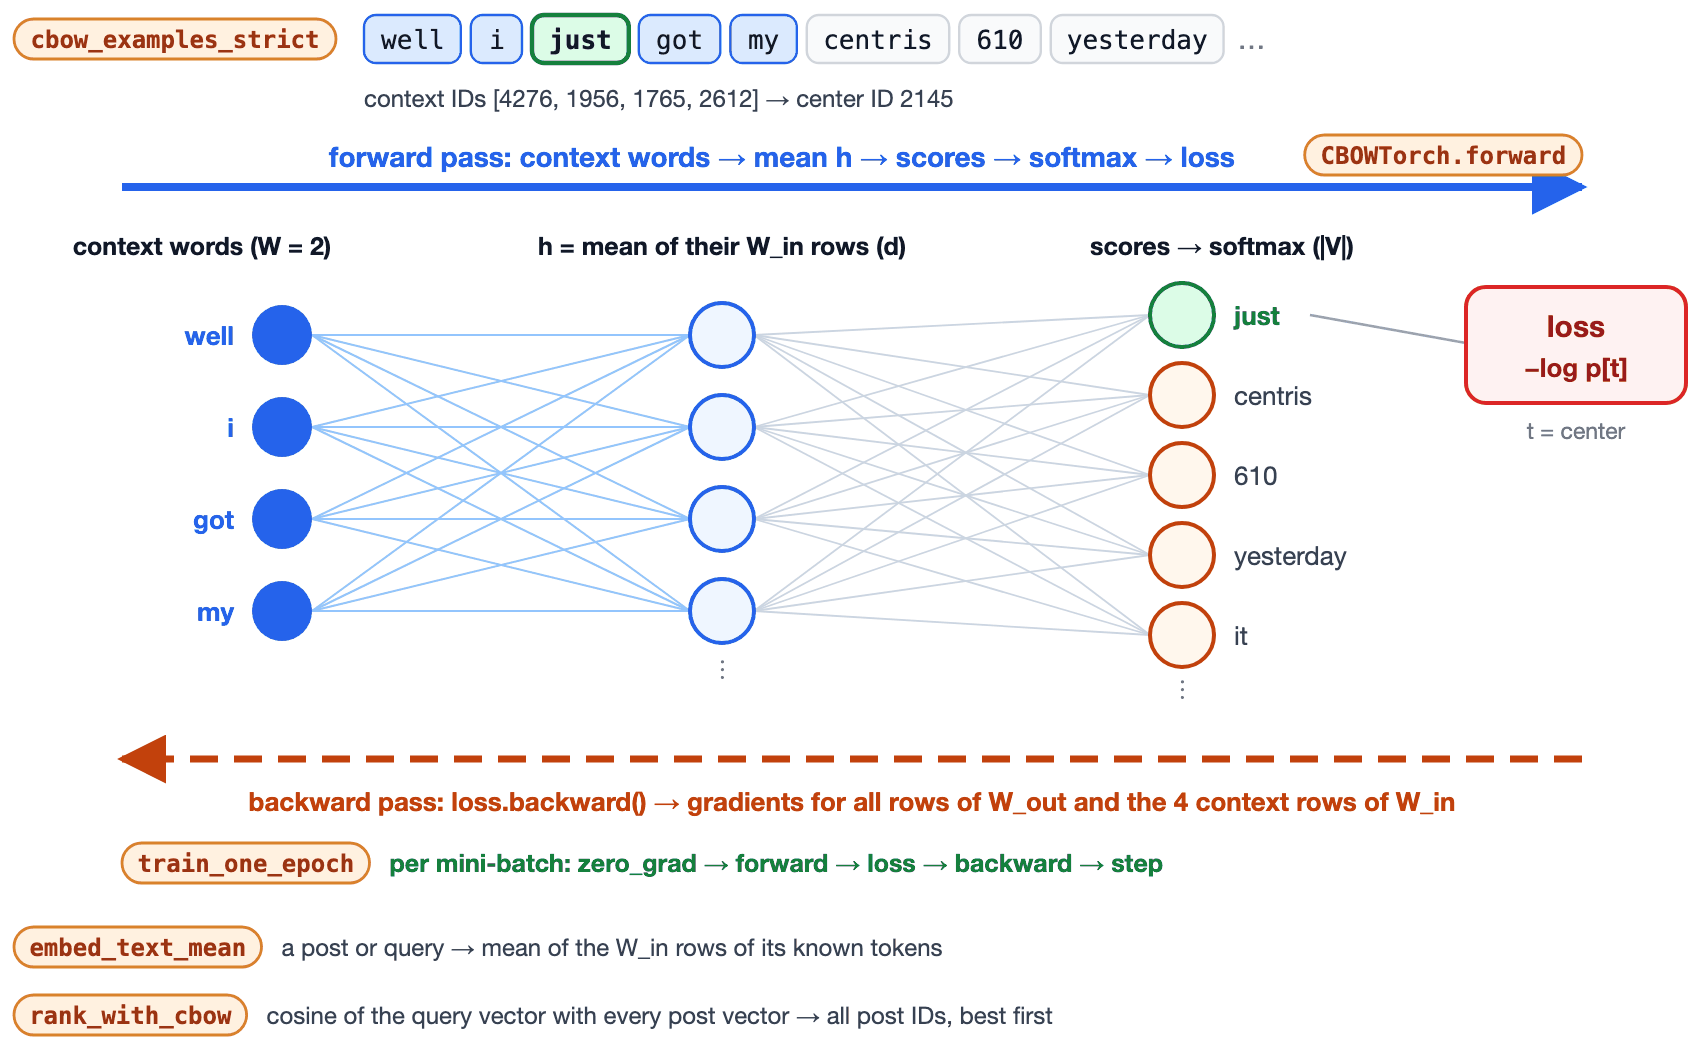" alt="Step 1, cbow_examples_strict: in training post 0 (well i just got my centris 610 yesterday ...), the center &#x27;just&#x27; with the window well, i, got, my gives the context IDs [4276, 1956, 1765, 2612] and the center ID 2145. CBOWTorch.forward (blue forward arrow): the four context words select their rows of W_in, which are averaged into h; W_out and b_out score every vocabulary word, softmax turns the scores into probabilities, and the loss is minus log p of the center word. train_one_epoch (dashed orange backward arrow): loss.backward() gives gradients to all rows of W_out and the four context rows of W_in, then the optimizer steps, for every mini-batch. embed_text_mean averages the W_in rows of the known tokens of a post or query; rank_with_cbow ranks all posts by the cosine with the query vector." width="720">

The figure shows the first training example of post 0 (forward pass in blue, backward pass in orange) and the function that implements each part.

---

### What is provided
- `train_tokenized`, `w2i`, `i2w`, and the `CBOWModelTorch` container from the Task 2 data cell; `TEST_DOCS`, `QUERIES`, `tokenize`, `cosine`, and `rank_by_score` from the Task 1 data cell.
- The `CBOWTorch` layers `in_embed` and `out` with a small Gaussian initialization.
- `cbow_train_torch(...)`: builds the examples, serves them in shuffled (seeded) mini-batches (`DataLoader` over a `TensorDataset`), creates the model, `nn.CrossEntropyLoss`, and `Adam`, and calls `train_one_epoch` once per epoch ($d = 100$, $W = 2$, batch size 256, 10 epochs, learning rate $10^{-3}$).
- The code that prints the first examples of post 0, trains the model, embeds the retrieval posts (`CBOW_TEST_EMBEDS`), and prints the CBOW top-5 posts of every query.

---

### What you should implement
1) `cbow_examples_strict` — build one example for every post and every center position with a full window: append the `2 * window` IDs of the **context words** (the left words, then the right words; the center word itself is **not** part of the context) to `contexts`, and the ID of the **center word** to `centers`. Return `contexts` and `centers` as two NumPy arrays of IDs (e.g. `np.array(..., dtype=np.int64)`) of shapes `(N, 2 * window)` and `(N,)`.
2) `CBOWTorch.forward` — `in_embed` → mean over the context words → `out`; return the logits of shape `(B, |V|)` (no softmax).
3) `train_one_epoch` — start with `model.train()`, then for **every mini-batch**: `zero_grad` → forward pass → loss → `backward` → `step`. Return the **mean training loss per example** as a `float`: $\frac{1}{N}\sum_{\text{batches}} \text{loss} \cdot \text{batch size}$.
4) `embed_text_mean` — return a NumPy array of shape `(d,)`: the mean of the rows of $W_{\text{in}}$ (`in_embed.weight`) of all tokens that are in `w2i` (a token that occurs twice counts twice), computed without gradients. If no token is in `w2i`, return a zero vector of shape `(d,)`, e.g. `np.zeros(cbow.dim, dtype=np.float32)`.
5) `rank_with_cbow` — embed the query with `embed_text_mean(tokenize(query_text), cbow)`, compute its `cosine` with every row of `doc_embeddings`, and return `rank_by_score(scores)`.

---

### Grading (7 pts)
One sub-task per function above:
- **2.1** `cbow_examples_strict`: full windows only, context order, arrays of shapes `(N, 2 * window)` and `(N,)`; the examples and their number match the expected output — **1.5 pts**
- **2.2** `CBOWTorch.forward`: mean of the context rows, then `out`; logits of shape `(B, |V|)` — **1.5 pts**
- **2.3** `train_one_epoch`: step order and mean loss per example; the epoch lines match the expected output — **1.5 pts**
- **2.4** `embed_text_mean`: mean of the `W_in` rows of the known tokens, zero vector for unknown text — **1.0 pt**
- **2.5** `rank_with_cbow`: mean query embedding, cosine scores, all IDs in order; the CBOW top-5 match the expected output — **1.5 pts**

> **Tips**
> • The seeds and the shuffle are fixed, so your epoch lines should match the expected output. If they do not, check the order of the training step and the mean-loss formula, and call the model once per mini-batch.
> • Training runs on the CPU in a few seconds.

In [8]:
# Step 1: training examples
def cbow_examples_strict(tokenized: list[list[str]], w2i: dict[str, int], window: int = 2) -> tuple[np.ndarray, np.ndarray]:
    """Return (contexts, centers): one example per center with exactly `window` words on each side."""
    ## YOUR_CODE_STARTS_HERE
    contexts = []
    centers = []
    for tokens in tokenized:
        for i in range(window, len(tokens) - window):
            context = [w2i[tokens[j]] for j in range(i - window, i + window + 1) if j != i]
            center = w2i[tokens[i]]
            contexts.append(context)
            centers.append(center)
    return np.array(contexts, dtype=np.int64).reshape(-1, 2 * window), np.array(centers, dtype=np.int64)
    ## YOUR_CODE_ENDS_HERE


# Step 2: the model
class CBOWTorch(nn.Module):
    def __init__(self, vocab_size: int, dim: int) -> None:
        super().__init__()
        self.in_embed = nn.Embedding(vocab_size, dim)  # W_in: (|V|, d)
        self.out = nn.Linear(dim, vocab_size)          # W_out: (|V|, d) and b_out: (|V|,)
        nn.init.normal_(self.in_embed.weight, mean=0.0, std=0.01)
        nn.init.normal_(self.out.weight, mean=0.0, std=0.01)
        nn.init.zeros_(self.out.bias)

    def forward(self, context_idx: torch.Tensor) -> torch.Tensor:
        """context_idx: (B, 2W) IDs of the context words; returns logits: (B, |V|)."""
        ## YOUR_CODE_STARTS_HERE
        context_embed = self.in_embed(context_idx)
        context_mean = torch.mean(context_embed, dim=1)
        logits = self.out(context_mean)
        return logits
        ## YOUR_CODE_ENDS_HERE


# Step 3: training
def train_one_epoch(model: CBOWTorch, loader: DataLoader, optimizer: optim.Optimizer,
                    criterion: nn.Module) -> float:
    """Run one optimization step per mini-batch and return the mean training loss per example."""
    ## YOUR_CODE_STARTS_HERE
    total_loss = 0.0
    num_examples = 0
    model.train()
    for context_idx, center_idx in loader:
        optimizer.zero_grad()
        logits = model(context_idx)
        loss = criterion(logits, center_idx)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * context_idx.size(0)
        num_examples += context_idx.size(0)
    mean_loss = total_loss / num_examples
    return mean_loss
    ## YOUR_CODE_ENDS_HERE


def cbow_train_torch(tokenized: list[list[str]], w2i: dict[str, int], i2w: dict[int, str], dim: int = 100,
                     window: int = 2, batch_size: int = 256, epochs: int = 10, lr: float = 1e-3,
                     seed: int = RANDOM_SEED) -> CBOWModelTorch:
    """Train CBOW with mini-batches and Adam (provided)."""
    contexts, centers = cbow_examples_strict(tokenized, w2i, window=window)
    print(f"[TASK2] CBOW data: {len(centers)} examples | V={len(w2i)} | d={dim} | window={window}")

    # Each item of the dataset is one (context IDs, center ID) example
    ds = TensorDataset(torch.tensor(contexts, dtype=torch.long), torch.tensor(centers, dtype=torch.long))
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))

    torch.manual_seed(seed)
    model = CBOWTorch(vocab_size=len(w2i), dim=dim)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    losses = []
    for ep in range(1, epochs + 1):
        losses.append(train_one_epoch(model, dl, optimizer, criterion))
        print(f"[TASK2] Epoch {ep:02d} | train loss {losses[-1]:.4f}")
    return CBOWModelTorch(w2i=w2i, i2w=i2w, model=model, dim=dim, window=window, losses=losses)


# Step 4: using the vectors
def embed_text_mean(tokens: list[str], cbow: CBOWModelTorch) -> np.ndarray:
    """Return the mean of the W_in rows of the known tokens, shape (d,); zeros if no token is known."""
    ## YOUR_CODE_STARTS_HERE
    known_indices = [cbow.w2i[token] for token in tokens if token in cbow.w2i]
    if not known_indices:
        return np.zeros(cbow.dim, dtype=np.float32)
    embeddings = cbow.model.in_embed(torch.tensor(known_indices, dtype=torch.long)).detach().numpy()
    mean_embedding = np.mean(embeddings, axis=0)
    return mean_embedding
    ## YOUR_CODE_ENDS_HERE


def rank_with_cbow(query_text: str, cbow: CBOWModelTorch, doc_embeddings: np.ndarray) -> list[int]:
    """Rank all documents by the cosine of their mean CBOW embedding with the mean CBOW embedding of the query."""
    ## YOUR_CODE_STARTS_HERE
    query_tokens = tokenize(query_text)
    query_embedding = embed_text_mean(query_tokens, cbow)
    similarities = np.array([cosine(query_embedding, doc_embedding) for doc_embedding in doc_embeddings])
    return rank_by_score(similarities)  
    ## YOUR_CODE_ENDS_HERE


# Step 1 on training post 0: its first three examples
post0_contexts, post0_centers = cbow_examples_strict(train_tokenized[:1], w2i, window=2)
print(f"[TASK2] Post 0 has {len(train_tokenized[0])} tokens and gives {len(post0_centers)} examples; the first three:")
for context, center in zip(post0_contexts[:3], post0_centers[:3]):
    print(f"[TASK2]   {[i2w[index] for index in context]} -> {i2w[center]!r}   IDs {context.tolist()} -> {center}")

# Steps 2 and 3: train CBOW
cbow = cbow_train_torch(train_tokenized, w2i, i2w, dim=100, window=2, batch_size=256, epochs=10, lr=1e-3,
                        seed=RANDOM_SEED)

# Step 4: rank the retrieval posts with mean CBOW embeddings
CBOW_TEST_EMBEDS = np.array([embed_text_mean(doc.tokens, cbow) for doc in TEST_DOCS])  # (num_docs, d)
cbow_top5_ids = {}
for query_text, label in QUERIES:
    top5 = rank_with_cbow(query_text, cbow, CBOW_TEST_EMBEDS)[:5]
    cbow_top5_ids[label] = top5
    print(f"[TASK2] Query ({label}): CBOW top-5 IDs {str(top5):<22} labels {[TEST_DOCS[doc_id].label for doc_id in top5]}")

# RESULT_CHECKING_POINT
print(f"[TASK2 RESULT_CHECKING_POINT] train loss epoch 1 -> 10: {cbow.losses[0]:.4f} -> {cbow.losses[-1]:.4f} | "
      f"CBOW top-1 IDs: {[cbow_top5_ids[label][0] for _, label in QUERIES]}")

[TASK2] Post 0 has 50 tokens and gives 46 examples; the first three:
[TASK2]   ['well', 'i', 'got', 'my'] -> 'just'   IDs [4276, 1956, 1765, 2612] -> 2145
[TASK2]   ['i', 'just', 'my', 'centris'] -> 'got'   IDs [1956, 2145, 2612, 833] -> 1765
[TASK2]   ['just', 'got', 'centris', '610'] -> 'my'   IDs [2145, 1765, 833, 213] -> 2612
[TASK2] CBOW data: 16259 examples | V=4407 | d=100 | window=2


[TASK2] Epoch 01 | train loss 8.3306
[TASK2] Epoch 02 | train loss 7.8236


[TASK2] Epoch 03 | train loss 7.1354
[TASK2] Epoch 04 | train loss 6.9129


[TASK2] Epoch 05 | train loss 6.8445
[TASK2] Epoch 06 | train loss 6.7923


[TASK2] Epoch 07 | train loss 6.7485
[TASK2] Epoch 08 | train loss 6.7092


[TASK2] Epoch 09 | train loss 6.6743
[TASK2] Epoch 10 | train loss 6.6402
[TASK2] Query (mac): CBOW top-5 IDs [99, 19, 81, 57, 20]   labels ['hockey', 'mac', 'hockey', 'autos', 'mac']
[TASK2] Query (space): CBOW top-5 IDs [48, 42, 50, 26, 86]   labels ['space', 'space', 'autos', 'space', 'hockey']
[TASK2] Query (autos): CBOW top-5 IDs [17, 81, 19, 39, 1]    labels ['mac', 'hockey', 'mac', 'space', 'mac']
[TASK2] Query (hockey): CBOW top-5 IDs [26, 76, 67, 46, 88]   labels ['space', 'hockey', 'autos', 'space', 'hockey']
[TASK2 RESULT_CHECKING_POINT] train loss epoch 1 -> 10: 8.3306 -> 6.6402 | CBOW top-1 IDs: [99, 48, 17, 26]


In [9]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. The examples should match exactly;
# losses and CBOW rankings may differ slightly on other hardware.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK2] Post 0 has 50 tokens and gives 46 examples; the first three:
# [TASK2]   ['well', 'i', 'got', 'my'] -> 'just'   IDs [4276, 1956, 1765, 2612] -> 2145
# [TASK2]   ['i', 'just', 'my', 'centris'] -> 'got'   IDs [1956, 2145, 2612, 833] -> 1765
# [TASK2]   ['just', 'got', 'centris', '610'] -> 'my'   IDs [2145, 1765, 833, 213] -> 2612
# [TASK2] CBOW data: 16259 examples | V=4407 | d=100 | window=2
# [TASK2] Epoch 01 | train loss 8.3306
# [TASK2] Epoch 02 | train loss 7.8236
# [TASK2] Epoch 03 | train loss 7.1354
# [TASK2] Epoch 04 | train loss 6.9129
# [TASK2] Epoch 05 | train loss 6.8445
# [TASK2] Epoch 06 | train loss 6.7923
# [TASK2] Epoch 07 | train loss 6.7485
# [TASK2] Epoch 08 | train loss 6.7092
# [TASK2] Epoch 09 | train loss 6.6743
# [TASK2] Epoch 10 | train loss 6.6402
# [TASK2] Query (mac): CBOW top-5 IDs [99, 19, 81, 57, 20]   labels ['hockey', 'mac', 'hockey', 'autos', 'mac']
# [TASK2] Query (space): CBOW top-5 IDs [48, 42, 50, 26, 86]   labels ['space', 'space', 'autos', 'space', 'hockey']
# [TASK2] Query (autos): CBOW top-5 IDs [17, 81, 19, 39, 1]    labels ['mac', 'hockey', 'mac', 'space', 'mac']
# [TASK2] Query (hockey): CBOW top-5 IDs [26, 76, 67, 46, 88]   labels ['space', 'hockey', 'autos', 'space', 'hockey']
# [TASK2 RESULT_CHECKING_POINT] train loss epoch 1 -> 10: 8.3306 -> 6.6402 | CBOW top-1 IDs: [99, 48, 17, 26]
#
# ---------------------------------------------------------------------------

# TASK 3 (7 pts): Evaluation with P@k, R@k, and MRR

**High-level overview.**
Evaluate four rankers (TF-IDF, BM25, LSA, and CBOW) on the four queries. Their rankings are **given** in `RANKINGS`: for every query, the IDs of the 25 posts each ranker puts first. A post is **relevant** for a query if it comes from the query's newsgroup, so every query has $|R| = 25$ relevant posts. You implement the ranking metrics of **PS 04** and compare the rankers with **P@5**, **R@25**, and **MRR**.

**Metrics.** For one query with the set $R$ of relevant posts, $TP@k$ counts the relevant posts among the first $k$ posts of the ranking, $FP@k$ the non-relevant ones, and $FN@k$ the relevant posts that are **not** among the first $k$. $\mathrm{rank}_q$ is the rank of the **first** relevant post for query $q$ (ranks start at 1):

$$
\mathrm{P@}k = \frac{TP@k}{TP@k + FP@k}, \qquad
\mathrm{R@}k = \frac{TP@k}{TP@k + FN@k} = \frac{TP@k}{|R|}, \qquad
\mathrm{RR}(q) = \frac{1}{\mathrm{rank}_q}, \qquad
\mathrm{MRR} = \frac{1}{|Q|}\sum_{q \in Q}\mathrm{RR}(q)
$$

P@k asks how many of the first $k$ posts are relevant; R@k asks how many of **all** relevant posts are among the first $k$; RR looks only at the first relevant post ($\mathrm{RR}(q) = 0$ if none of the given posts is relevant). For example, the ranking `[7, 3, 9, 4]` with $R = \{3, 4, 8\}$ has $\mathrm{P@}2 = \frac{1}{2}$, $\mathrm{R@}2 = \frac{1}{3}$, and $\mathrm{RR} = \frac{1}{2}$ (the first relevant post, 3, is at rank 2).

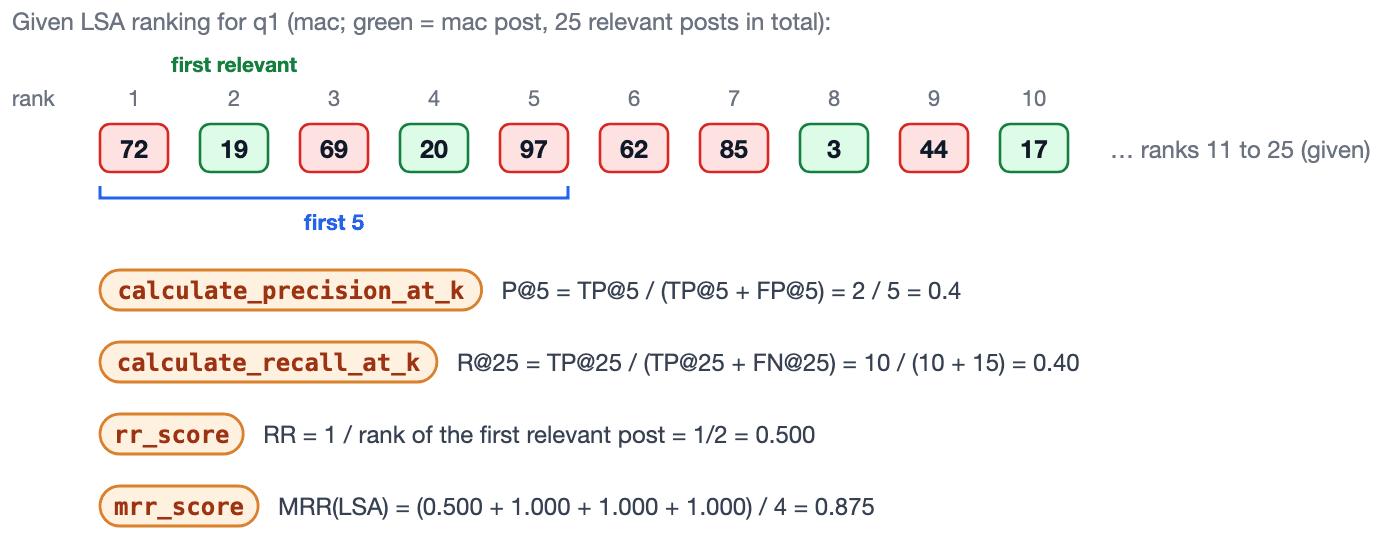

The figure shows one given ranking (LSA, query `q1`, label *mac*) and the values your functions must produce for it.

---

### What is provided
- `RANKINGS` (for every ranker, one entry per query with `query_id`, `label`, and the 25-post `ranking`) and `RELEVANT_SETS` (the relevant post IDs of every `query_id`) from the Task 3 data cell.
- The cut-offs `PRECISION_CUTOFF = 5` and `RECALL_CUTOFF = 25`, and the code that evaluates every ranker and prints P@5, R@25, RR, and MRR.

---

### What you should implement
1) `calculate_precision_at_k` — $TP@k / (TP@k + FP@k)$ for the first `k` retrieved IDs; `0.0` if that list is empty.
2) `calculate_recall_at_k` — $TP@k / (TP@k + FN@k)$; `0.0` if there are no relevant IDs.
3) `rr_score` — `1 / rank` of the first relevant ID, with ranks starting at 1; `0.0` if no ID in the ranking is relevant.
4) `mrr_score` — the mean of `rr_score` over all queries (pairs of a ranking and its relevant set); `0.0` for no queries.

---

### Grading (7 pts)
One sub-task per function above:
- **3.1** `calculate_precision_at_k`: relevant share of the first `k`; the P@5 values match the expected output — **1.5 pts**
- **3.2** `calculate_recall_at_k`: share of all relevant posts among the first `k`; the R@25 values match the expected output — **1.5 pts**
- **3.3** `rr_score`: rank of the first relevant post, 0 if there is none; the RR values match the expected output — **2.5 pts**
- **3.4** `mrr_score`: mean over all queries, including queries with RR 0; the MRR values match the expected output — **1.5 pts**

> **Tips**
> • Ranks start at 1: the first ID has rank 1, so RR is `1.0 / rank` (or `1.0 / (index + 1)`).

In [10]:
def calculate_precision_at_k(retrieved: list[int], relevant: set[int], k: int) -> float:
    """Precision of the top k retrieved documents."""
    ## YOUR_CODE_STARTS_HERE
    top_k_retrieved = retrieved[:k]
    if not top_k_retrieved:
        return 0.0
    retrieved_relevant = sum(1 for doc_id in top_k_retrieved if doc_id in relevant)
    precision = retrieved_relevant / len(top_k_retrieved)
    return precision
    ## YOUR_CODE_ENDS_HERE


def calculate_recall_at_k(retrieved: list[int], relevant: set[int], k: int) -> float:
    """Share of all relevant documents that appear in the top k."""
    ## YOUR_CODE_STARTS_HERE
    if k <= 0:
        return 0.0
    relevant_retrieved = sum(1 for doc_id in retrieved[:k] if doc_id in relevant)
    recall = relevant_retrieved / len(relevant) if relevant else 0.0
    return recall
    ## YOUR_CODE_ENDS_HERE


def rr_score(ranking: list[int], relevant: set[int]) -> float:
    """1 / rank of the first relevant document; 0.0 if there is none."""
    ## YOUR_CODE_STARTS_HERE
    if not relevant:
        return 0.0
    for rank, doc_id in enumerate(ranking, start=1):
        if doc_id in relevant:
            return 1.0 / rank
    return 0.0       
    ## YOUR_CODE_ENDS_HERE


def mrr_score(rankings: list[list[int]], relevant_sets: list[set[int]]) -> float:
    """Mean of rr_score over all queries; 0.0 if there are no queries."""
    ## YOUR_CODE_STARTS_HERE
    if not rankings:
        return 0.0
    rr_scores = [rr_score(ranking, relevant) for ranking, relevant in zip(rankings, relevant_sets)]
    mrr = sum(rr_scores) / len(rr_scores)
    return mrr  
    ## YOUR_CODE_ENDS_HERE


PRECISION_CUTOFF = 5   # P@5: how many of the first 5 posts are relevant
RECALL_CUTOFF = 25     # R@25: how many of the 25 relevant posts are among the 25 given posts
query_order = [f"{entry['query_id']} ({entry['label']})" for entry in RANKINGS["TF-IDF"]]
print(f"[TASK3] Query order: {', '.join(query_order)}")
print(f"[TASK3] {'Ranker':<7} {'P@5 per query':<16} {'R@25 per query':<20} {'RR per query':<24} "
      f"{'mean P@5':<9} {'mean R@25':<10} MRR")
results_by_ranker = {}
for ranker, entries in RANKINGS.items():
    rankings = [entry["ranking"] for entry in entries]
    relevant_sets = [RELEVANT_SETS[entry["query_id"]] for entry in entries]
    precision_at_5, recall_at_25, reciprocal_ranks = [], [], []
    for ranking, relevant in zip(rankings, relevant_sets):
        precision_at_5.append(calculate_precision_at_k(ranking, relevant, PRECISION_CUTOFF))
        recall_at_25.append(calculate_recall_at_k(ranking, relevant, RECALL_CUTOFF))
        reciprocal_ranks.append(rr_score(ranking, relevant))
    mrr = mrr_score(rankings, relevant_sets)
    results_by_ranker[ranker] = {"precision_at_5": precision_at_5, "recall_at_25": recall_at_25,
                                 "reciprocal_ranks": reciprocal_ranks, "mrr": mrr}
    print(f"[TASK3] {ranker:<7} {' '.join(f'{value:.1f}' for value in precision_at_5):<16} "
          f"{' '.join(f'{value:.2f}' for value in recall_at_25):<20} "
          f"{' '.join(f'{value:.3f}' for value in reciprocal_ranks):<24} "
          f"{np.mean(precision_at_5):<9.3f} {np.mean(recall_at_25):<10.3f} {mrr:.3f}")

# RESULT_CHECKING_POINT
print("[TASK3 RESULT_CHECKING_POINT] MRR: " + " | ".join(
    f"{ranker} {result['mrr']:.3f}" for ranker, result in results_by_ranker.items()))

[TASK3] Query order: q1 (mac), q2 (space), q3 (autos), q4 (hockey)
[TASK3] Ranker  P@5 per query    R@25 per query       RR per query             mean P@5  mean R@25  MRR
[TASK3] TF-IDF  0.4 0.8 0.4 1.0  0.40 0.24 0.52 0.36  1.000 1.000 1.000 1.000  0.650     0.380      1.000
[TASK3] BM25    0.8 0.8 0.4 1.0  0.32 0.28 0.52 0.36  1.000 1.000 1.000 1.000  0.750     0.370      1.000
[TASK3] LSA     0.4 0.2 0.8 0.6  0.40 0.24 0.60 0.36  0.500 1.000 1.000 1.000  0.500     0.400      0.875
[TASK3] CBOW    0.4 0.6 0.0 0.4  0.28 0.28 0.28 0.36  0.500 1.000 0.100 0.500  0.350     0.300      0.525
[TASK3 RESULT_CHECKING_POINT] MRR: TF-IDF 1.000 | BM25 1.000 | LSA 0.875 | CBOW 0.525


In [11]:
# ------------------------- TESTS & EXPECTED OUTPUT -------------------------
#
# Your output of the cell above should match these lines. All values should match exactly.
# Hardcoding these values gives 0 points for the whole task.
#
# [TASK3] Query order: q1 (mac), q2 (space), q3 (autos), q4 (hockey)
# [TASK3] Ranker  P@5 per query    R@25 per query       RR per query             mean P@5  mean R@25  MRR
# [TASK3] TF-IDF  0.4 0.8 0.4 1.0  0.40 0.24 0.52 0.36  1.000 1.000 1.000 1.000  0.650     0.380      1.000
# [TASK3] BM25    0.8 0.8 0.4 1.0  0.32 0.28 0.52 0.36  1.000 1.000 1.000 1.000  0.750     0.370      1.000
# [TASK3] LSA     0.4 0.2 0.8 0.6  0.40 0.24 0.60 0.36  0.500 1.000 1.000 1.000  0.500     0.400      0.875
# [TASK3] CBOW    0.4 0.6 0.0 0.4  0.28 0.28 0.28 0.36  0.500 1.000 0.100 0.500  0.350     0.300      0.525
# [TASK3 RESULT_CHECKING_POINT] MRR: TF-IDF 1.000 | BM25 1.000 | LSA 0.875 | CBOW 0.525
#
# ---------------------------------------------------------------------------

# BONUS (2 pts): Solve one task with an LLM

**Goal.**
Choose **one** task (Task 1, Task 2, or Task 3), let an **LLM** solve it, run the LLM's code, and compare its result with the task's `TESTS & EXPECTED OUTPUT` cell and with your own solution.

**Steps.**
1. Give the LLM the task's description (the Markdown cell) and the code it depends on: the task's data-and-helpers cell and the task code cell with the empty `YOUR_CODE` regions. Ask it for the code of **all** functions you implement in that task.
2. Run the generated code in a **copy of this notebook**: paste it into the task code cell of the copy and run the copy from the top. This keeps your own solution here unchanged. Do not submit the copy.
3. Fill in the answer cell below.

**What to deliver in the answer cell.**
1) **LLM used**: (name + version, e.g., "Llama-3-8B-Instruct", "GPT-x", "Claude-x", "Mistral-x", etc.). You may use any LLMs through any interface (API, web UI, local inference).
2) **Generated code**: the LLM's generated code for the task's functions. If you needed several attempts, paste the last one.
3) **Output**: the `[TASKn RESULT_CHECKING_POINT]` line that the LLM's code printed, or the error message if it failed.
4) **Comparison and reflection** (3–6 sentences): Does the LLM's output match the expected output? Where does the LLM's code differ from your solution (e.g., a missing step, a different formula, extra code)? What did the LLM do well, and what did it get wrong?

**Grading (2 pts):**

- deliverables 1–3 complete — **1 pt**.
- deliverable 4: a brief comparison and reflection that says whether the LLM matched the expected output, how its code differs from yours, and what it did well vs wrong — **1 pt**

> **No code required for calling the LLM.** You do not need to submit your prompts or any code you used to call the LLM (e.g., API scripts). An LLM solution that fails can still earn the full bonus if you document and analyze its failure well in your **Comparison and reflection**. Provide only the deliverables listed above.

**1) LLM used (name and version):**

```text
Claude Opus 5.5 (claude-opus-5-5), Anthropic, used through Claude Code (CLI)
```

**2) Generated code** (last attempt):

```python
def calculate_precision_at_k(retrieved: list[int], relevant: set[int], k: int) -> float:
    """Precision of the top k retrieved documents."""
    ## YOUR_CODE_STARTS_HERE
    top_k = retrieved[:k]
    if not top_k:
        return 0.0
    true_positives = sum(1 for doc_id in top_k if doc_id in relevant)
    return true_positives / len(top_k)
    ## YOUR_CODE_ENDS_HERE


def calculate_recall_at_k(retrieved: list[int], relevant: set[int], k: int) -> float:
    """Share of all relevant documents that appear in the top k."""
    ## YOUR_CODE_STARTS_HERE
    if not relevant:
        return 0.0
    true_positives = sum(1 for doc_id in retrieved[:k] if doc_id in relevant)
    return true_positives / len(relevant)
    ## YOUR_CODE_ENDS_HERE


def rr_score(ranking: list[int], relevant: set[int]) -> float:
    """1 / rank of the first relevant document; 0.0 if there is none."""
    ## YOUR_CODE_STARTS_HERE
    for rank, doc_id in enumerate(ranking, start=1):
        if doc_id in relevant:
            return 1.0 / rank
    return 0.0
    ## YOUR_CODE_ENDS_HERE


def mrr_score(rankings: list[list[int]], relevant_sets: list[set[int]]) -> float:
    """Mean of rr_score over all queries; 0.0 if there are no queries."""
    ## YOUR_CODE_STARTS_HERE
    if not rankings:
        return 0.0
    reciprocal_ranks = [rr_score(ranking, relevant) for ranking, relevant in zip(rankings, relevant_sets)]
    return sum(reciprocal_ranks) / len(reciprocal_ranks)
    ## YOUR_CODE_ENDS_HERE
```

**3) Output** (`[TASKn RESULT_CHECKING_POINT]` line or error message):

```text
[TASK3 RESULT_CHECKING_POINT] MRR: TF-IDF 1.000 | BM25 1.000 | LSA 0.875 | CBOW 0.525
```

**4) Comparison and reflection:**

```text
The LLM's output matches the expected output exactly: all seven [TASK3] lines (P@5, R@25 and RR per
query, the means, and MRR) are identical to the TESTS & EXPECTED OUTPUT cell, and the code also gives
P@2 = 0.5, R@2 = 1/3 and RR = 0.5 for the worked example [7, 3, 9, 4] with R = {3, 4, 8}.
It handles every edge case the task names (empty list -> 0.0, no relevant posts -> 0.0, no relevant
post in the ranking -> RR 0.0, no queries -> MRR 0.0), and mrr_score reuses rr_score, so a query with
RR 0 still counts in the mean.
Its code is shorter than mine: my functions add guards that never change a result (k <= 0 in P@k and
R@k, an empty relevant set in rr_score) and store intermediate variables.
The one real difference was in calculate_precision_at_k: my first version divided by k, while the LLM
divided by len(retrieved[:k]), i.e. TP@k + FP@k as in the task's formula; both give the same values for
these 25-post rankings but differ for a ranking shorter than k, so I changed mine to the LLM's version.
It got nothing wrong, but the test was easy for it: the four functions are short, standard ranking
metrics, and Claude Code had the whole notebook open, including the expected output, so it was not a
blind attempt.
```

# End of HW 02

Before submitting, restart the runtime and run all cells. Confirm that your notebook contains your own work only.